# 13 · Pair features: turning an account and a candidate into numbers

**The question this step answers:** XGBoost and random forests (next step, Task 3.2) can't read text. How do we describe "this account, with this candidate group" in numbers, so a model can learn which candidate is the right one?

**Where it sits in the pipeline:** between the shortlist (notebooks 07 and 12) and the learning methods:

```
account name -> shortlist of 10 (07, 12) -> 10 rows of numbers (this step) -> a model scores each row (3.2) -> calibration (09) -> auto or review
```

**The code:** `src/d1/mapper/features.py`
- `PairFeaturizer`: fitted once on train, then turns any account and its shortlist into a 10 × 27 table;
- `account_features` and `lexical_features`: the features that need no embeddings;
- `training_pairs`: all train accounts stacked into one table, with a 1 on each right group.

*Running this notebook loads bge-m3 and fits the featurizer on the 12,000 train accounts: about two minutes.*

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from d1.config import load_config
from d1.datagen.schema import CompanyAccount
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import GRID, INK, INK_2, MUTED, SINGLE, SURFACE, apply_style, pct
from d1.mapper.embed import SentenceTransformerEmbedder
from d1.mapper.features import BASE_FEATURES, PairFeaturizer, account_features, training_pairs
from d1.mapper.methods.base import AccountIn
from d1.mapper.pipeline import build_retriever

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 60)
K = config.models.mapping.candidates_k

load = lambda split: [CompanyAccount.model_validate_json(line) for line in open(config.data.generated_dir / f"{split}.jsonl")]
train, dev = load("train"), load("dev")
retriever = build_retriever(config, SentenceTransformerEmbedder(config.models.embedding_model), chart)

start = time.time()
featurizer = PairFeaturizer(retriever, chart).fit(train)
print(f"fitted on {len(train):,} train accounts in {time.time() - start:.0f} s; group_text: {retriever.group_text}; {len(featurizer.feature_names)} features")

/Users/vincenzovantornout/Desktop/Work Projects/Work Projects/Data & AI Resume/D1 - Consolidation Copilot/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 23:05:28.387000 56692 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 65186.93it/s]

fitted on 11,999 train accounts in 28 s; group_text: average; 27 features


## 1. One account, ten rows

An LLM-written dev account of a construction company: **"En-cours chantier Uccle - Av. Brugmann"** (work in progress on a building site), code 320200. Its right group is **320** *Work in Progress - Acquisition Value*.

The shortlist gives its 10 candidates. The featurizer turns each into one row. The first 11 columns:

In [2]:
row = next(r for r in dev if r.name == "En-cours chantier Uccle - Av. Brugmann")
account = AccountIn(account_id=row.account_id, name=row.name, code=row.code)
(shortlist,) = retriever.top_k([row.name], K)
(matrix,) = featurizer.transform([account], [shortlist])
table = pd.DataFrame(matrix, columns=featurizer.feature_names)
table.insert(0, "candidate", [f"{c.code} {by_code[c.code].name_en[:32]}" for c in shortlist])
table.insert(1, "right?", ["✔" if c.code == row.target_code else "" for c in shortlist])
print(f"{row.account_id}  code {row.code}  ({row.code_scheme} scheme)  right group {row.target_code}")
display(table[["candidate", "right?"] + BASE_FEATURES].style.format(precision=3).hide(axis="index"))

dev-c041-009  code 320200  (llm scheme)  right group 320


candidate,right?,cosine,rank,gap_to_top,parent_cosine,fuzzy_wratio,token_jaccard,code_prefix_match,class_digit_match,name_len,n_digits,is_bilingual
370 Contracts in Progress - Acquisit,,0.458,1.000,0.000,0.530,0.442,0.200,0.000,1.000,38.000,6.000,0.000
717 Increase (Decrease) in Contracts,,0.445,2.000,0.013,0.416,0.855,0.182,0.000,0.000,38.000,6.000,0.000
320 Work in Progress - Acquisition V,✔,0.444,3.000,0.014,0.576,0.506,0.200,1.000,1.000,38.000,6.000,0.000
221 Buildings,,0.430,4.000,0.028,0.426,0.428,0.000,0.000,0.000,38.000,6.000,0.000
371 Contracts in Progress - Profit R,,0.430,5.000,0.028,0.530,0.855,0.182,0.000,1.000,38.000,6.000,0.000
632 Amounts Written Off Contracts in,,0.423,6.000,0.035,0.339,0.855,0.167,0.000,0.000,38.000,6.000,0.000
712 Increase (Decrease) in Stocks of,,0.422,7.000,0.036,0.416,0.855,0.077,0.000,0.000,38.000,6.000,0.000
426 Advance Payments on Contract in,,0.419,8.000,0.039,0.310,0.395,0.000,0.000,0.000,38.000,6.000,0.000
491 Accrued Income,,0.417,9.000,0.040,0.433,0.389,0.000,0.000,0.000,38.000,6.000,0.000
499 Suspense Accounts,,0.417,10.000,0.041,0.433,0.504,0.000,0.000,0.000,38.000,6.000,0.000


Read the right group's row (320, rank 3) against the others:

- **`cosine`, `rank`, `gap_to_top`** come straight from the shortlist. 320 is third, 0.014 behind number 1 (370 *Contracts in Progress*). On meaning alone, the embeddings baseline picks 370 and is wrong.
- **`parent_cosine`:** the account against the candidate's *parent* group. 320's parent is *Work in Progress* (32), 370's is *Contracts in Progress* (37). Here 320 has the highest parent cosine of the ten (0.576 against 0.530): "en-cours chantier" is closer to work in progress in general than to contracts.
- **`fuzzy_wratio`, `token_jaccard`:** letters and shared words, in the candidate's best language. They don't single out 320. Fuzzy even prefers 717, 371, 632 and 712 (0.855), because their French names contain "commandes **en cours** d'exécution": WRatio rewards a name that partly contains the other. Word overlap ties 320 with 370 (0.20).
- **`code_prefix_match`:** 1 only for 320, because the code 320200 starts with 320. **`class_digit_match`:** 1 for every class-3 candidate (370, 320, 371).
- **`name_len`, `n_digits`, `is_bilingual`:** the same on all ten rows. They say nothing alone, but a tree can use them to decide *how much to trust* the others. For example, 6 digits means the code is PCMN-style, so its prefix is worth trusting.

So the signals disagree. The cosine and fuzzy point elsewhere, while the code prefix and the parent cosine point at 320, with the cosine only 0.014 behind. Learning which signal to trust, and when, is exactly what the model in Task 3.2 is for.

The other 16 columns, `emb_pca_0` to `emb_pca_15`, are in section 3.

## 2. The account code: a giveaway, or a trap

Half the companies number their accounts PCMN-style, so the first three digits are *usually* the right group. The other half use an old company numbering. On train:

In [3]:
codes = pd.DataFrame([{"scheme": r.code_scheme, "digits": account_features(r.name, r.code)["n_digits"],
                       "starts with the right group": r.code.startswith(r.target_code)} for r in train])
summary = codes.groupby("scheme").agg(accounts=("digits", "size"), digits=("digits", lambda d: ", ".join(str(v) for v in sorted(d.unique()))),
                                      right_prefix=("starts with the right group", "mean")).reindex(["pcmn", "llm", "legacy"])
summary["share of train"] = summary["accounts"] / len(train)
display(summary.rename(columns={"right_prefix": "code starts with the right group"})
        .style.format({"code starts with the right group": "{:.0%}", "share of train": "{:.0%}"}))

,accounts,digits,code starts with the right group,share of train
scheme,,,,
pcmn,5000,6,96%,42%
llm,1000,"4, 5, 6",96%,8%
legacy,5999,4,0%,50%


- **`pcmn`** (rule-based companies that number like the standard chart) and **`llm`** (the LLM's own codes): the code starts with the right group **96% of the time**. A Belgian company that follows PCMN numbering mostly hands you the answer, and a mapper should use it.
- **The other 4% are misfiled on purpose:** booked under a *neighbouring* group's number, as a bookkeeper who picked the wrong sub-account would (`misfiled_code`, added after Task 3.2). Without them, a matching prefix was right 100% of the time in our data, and the rerankers learned to trust it blindly, which real companies would punish.
- **`legacy`:** **never**, by design (notebook 03). Worse, an old 4-digit code can start with a *wrong* group's code by accident:

In [4]:
trap = next(r for r in dev if r.name == "Ouderdoms- en overlevingspensioenen")
(trap_list,) = retriever.top_k([trap.name], K)
(trap_matrix,) = featurizer.transform([AccountIn(account_id=trap.account_id, name=trap.name, code=trap.code)], [trap_list])
t = pd.DataFrame(trap_matrix[:, [featurizer.feature_names.index(f) for f in ("cosine", "rank", "code_prefix_match", "n_digits")]],
                 columns=["cosine", "rank", "code_prefix_match", "n_digits"])
t.insert(0, "candidate", [f"{c.code} {by_code[c.code].name_en[:40]}" for c in trap_list])
t.insert(1, "right?", ["✔" if c.code == trap.target_code else "" for c in trap_list])
print(f"{trap.name!r}  code {trap.code} ({trap.code_scheme})  right group {trap.target_code} {by_code[trap.target_code].name_en}")
display(t.head(5).style.format(precision=3).hide(axis="index"))

'Ouderdoms- en overlevingspensioenen'  code 1600 (legacy)  right group 624 Retirement and Survivors' Pensions


candidate,right?,cosine,rank,code_prefix_match,n_digits
624 Retirement and Survivors' Pensions,✔,0.581,1.000,0.000,4.000
160 Provisions for Pensions and Similar Obli,,0.492,2.000,1.000,4.000
635 Provisions for Pensions and Similar Obli,,0.475,3.000,0.000,4.000
"618 Remuneration, Premiums for Extra Statuto",,0.452,4.000,0.000,4.000
764 Other Non-Recurring Operating Income,,0.423,5.000,0.000,4.000


Code 1600 starts with 160 *Provisions for Pensions*, a balance-sheet group, while the account is the pension *cost* (624). A model that trusted every prefix would be confidently wrong here. That's why `n_digits` is a feature: the model can learn "a prefix match counts on a 6-digit code, not on a 4-digit one". In dev, 6 legacy accounts have such a misleading prefix among their top 3 candidates, out of 1,700.

## 3. The meaning features: 16 numbers from 1,024

The cosine is one number: *how much* the account and the group agree. Behind it are 1,024 numbers, the element-wise product of the two vectors (their sum *is* the cosine). That product says *on what* they agree: on "this is about staff", on "this is a balance-sheet item", and so on.

1,024 numbers per row is too many for 12,000 training accounts, so a **PCA** keeps the 16 directions along which these products vary most:
1. **Fitted on train only,** on each train account paired with its *right* group: 12,000 products. `fit()` refuses dev or test rows.
2. **Applied unchanged** to every candidate of every account (dev, test, new companies): `(product − mean) × components`.

How much of the variation the 16 keep:

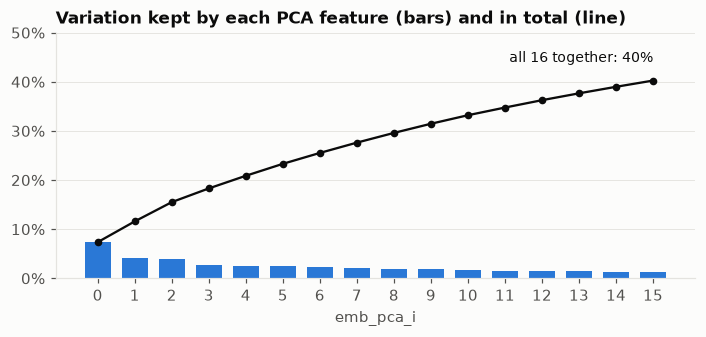

In [5]:
explained = np.array(featurizer.explained_variance)
fig, ax = plt.subplots(figsize=(7.5, 2.9))
ax.bar(np.arange(len(explained)), explained, color=SINGLE, width=0.7)
ax.plot(np.arange(len(explained)), np.cumsum(explained), color=INK, marker="o", markersize=4, linewidth=1.5)
ax.annotate(f"all 16 together: {explained.sum():.0%}", (len(explained) - 1, explained.sum()), xytext=(0, 10), textcoords="offset points", ha="right", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, max(0.5, explained.sum() + 0.08))
ax.set_xticks(np.arange(len(explained)), [str(i) for i in range(len(explained))])
ax.set_xlabel("emb_pca_i")
ax.yaxis.set_major_formatter(pct())
ax.grid(axis="x", visible=False)
ax.set_title("Variation kept by each PCA feature (bars) and in total (line)")
plt.show()

The 16 features keep about 40% of the variation, not all of it. Would more directions be better? First, how many it would take: the same PCA with all directions, on the same 12,000 train products.

In [6]:
from sklearn.decomposition import PCA

index = {c: i for i, c in enumerate(retriever.codes)}
products = featurizer._encode([r.name for r in train]) * retriever.standard_embeddings[[index[r.target_code] for r in train]]
kept = np.cumsum(PCA(svd_solver="full").fit(products).explained_variance_ratio_)
sizes = [4, 8, 16, 32, 64, 128, 256, 512]
display(pd.DataFrame({"variation kept": [kept[k - 1] for k in sizes]}, index=pd.Index(sizes, name="directions")).T.style.format("{:.0%}"))
for share in (0.5, 0.8, 0.9):
    print(f"{share:.0%} of the variation needs {int(np.searchsorted(kept, share)) + 1} directions")

directions,4,8,16,32,64,128,256,512
variation kept,18%,28%,40%,55%,69%,81%,90%,97%


50% of the variation needs 26 directions
80% of the variation needs 120 directions
90% of the variation needs 250 directions


**About 120 directions for 80%, 250 for 90%.** bge-m3 spreads its meaning thinly over all 1,024 numbers, so no small set of directions holds most of it.

**But "variation kept" is not what the model needs:**
- **PCA keeps what varies most, not what predicts best.** The biggest directions mostly say what *topic* a pair is about (staff, VAT, stock). Whether *this* candidate is the right one is mostly in the other 11 features.
- **The cosine already covers all 1,024 numbers.** It is their sum. The PCA features only add the *shape* of the agreement.
- **More meaning features make memorizing easier.** With 128 of them, a tree can learn "this pattern means group 604" from the train companies, instead of learning how matching works.

A quick check (one untuned gradient-boosting model on dev, one run) found top-1 83.2% with no PCA features, 83.8% with 16 and 84.7% with 64, with nothing more at 128. That is one point, about 35 accounts, close to the noise of one run. **So 16 stays for now, and the PCA size is tested properly in Task 3.2** (notebook 14), next to the learning curve and the intervals over companies.

## 4. Which features tell right from wrong, one at a time

Every dev account and its 10 candidates give 35,000 rows, 3,240 of them right (accounts whose right group is on the shortlist). For each feature alone: the **AUC**, the chance that a random right row scores higher than a random wrong one. 0.5 is no signal, 1.0 perfect. For `rank` and `gap_to_top`, lower means better, so their AUC is computed the other way round.

35,000 dev rows, 3,240 right (3,500 accounts)


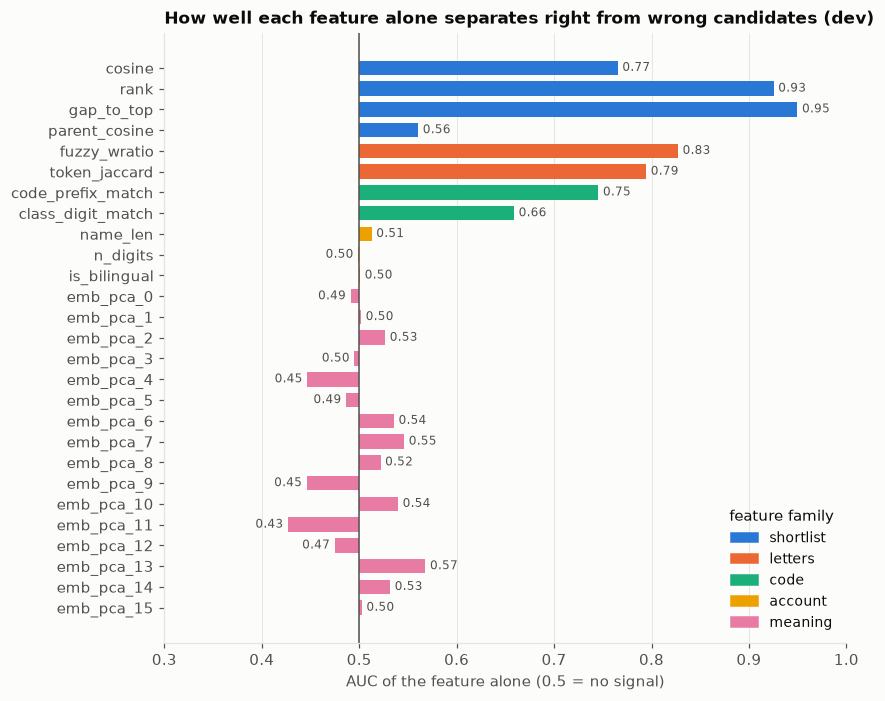

In [7]:
dev_shortlists = retriever.top_k([r.name for r in dev], K)
Xd, yd, gd = training_pairs(dev, dev_shortlists, featurizer)
LOWER_IS_BETTER = {"rank", "gap_to_top"}
FAMILY = {"cosine": "shortlist", "rank": "shortlist", "gap_to_top": "shortlist", "parent_cosine": "shortlist",
          "fuzzy_wratio": "letters", "token_jaccard": "letters", "code_prefix_match": "code", "class_digit_match": "code",
          "name_len": "account", "n_digits": "account", "is_bilingual": "account"}
FAMILY_COLORS = {"shortlist": "#2a78d6", "letters": "#eb6834", "code": "#1baf7a", "account": "#eda100", "meaning": "#e87ba4"}
auc = pd.DataFrame([{"feature": f, "family": FAMILY.get(f, "meaning"),
                     "AUC": roc_auc_score(yd, -Xd[:, i] if f in LOWER_IS_BETTER else Xd[:, i])}
                    for i, f in enumerate(featurizer.feature_names)])
print(f"{len(yd):,} dev rows, {yd.sum():,} right ({len(dev):,} accounts)")

fig, ax = plt.subplots(figsize=(8, 7.2))
order = auc.iloc[::-1]
bars = ax.barh(order["feature"], order["AUC"] - 0.5, left=0.5, color=[FAMILY_COLORS[f] for f in order["family"]], height=0.7)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in order["AUC"]], padding=3, fontsize=8, color=INK_2)
ax.axvline(0.5, color=INK_2, linewidth=1)
ax.set_xlim(0.3, 1.0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC of the feature alone (0.5 = no signal)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), title="feature family", loc="lower right", fontsize=9)
ax.set_title("How well each feature alone separates right from wrong candidates (dev)")
plt.show()

- **The gap to number 1 and the rank are the strongest single signals.** That's the shortlist's own ordering: the right group is usually at or near the top.
- **The letters come next.** Fuzzy and word overlap catch the rule-based names, which are distorted official names.
- **The code prefix** is strong but only on half the accounts: it's 0 for the right group on every legacy account.
- **The account features sit at 0.5 by construction:** they're the same on all ten rows of an account, so alone they can't pick a row. Their use is in combination, as in the trap of section 2.
- **The meaning features are weak alone (0.43 to 0.57).** Below 0.5 doesn't mean harmful: the sign of a PCA direction is arbitrary, so 0.43 carries as much signal as 0.57, pointing the other way. Each is one direction out of 1,024, and any value they have will show up only in combination.

AUC alone undersells combinations. A model that sees "rank 3, but the only code prefix match, and the best word overlap" can pick 320 in section 1, where no single column can.

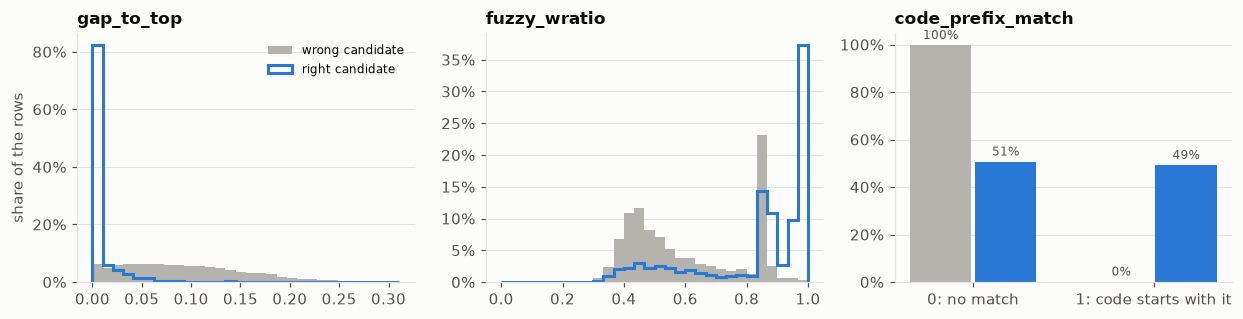

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.0))
for ax, f in zip(axes, ["gap_to_top", "fuzzy_wratio", "code_prefix_match"]):
    values = Xd[:, featurizer.feature_names.index(f)]
    if f == "code_prefix_match":  # two values: side-by-side bars
        for offset, (label, mask, color) in zip([-0.18, 0.18], [("wrong candidate", yd == 0, MUTED), ("right candidate", yd == 1, SINGLE)]):
            shares = [(values[mask] == v).mean() for v in (0, 1)]
            bars = ax.bar(np.array([0, 1]) + offset, shares, width=0.34, color=color, label=label)
            ax.bar_label(bars, labels=[f"{s:.0%}" for s in shares], padding=2, fontsize=8, color=INK_2)
        ax.set_xticks([0, 1], ["0: no match", "1: code starts with it"])
    else:  # wrong ones filled grey, right ones as a blue outline on top, each as a share of its own kind
        bins = np.linspace(values.min(), values.max(), 31)
        ax.hist(values[yd == 0], bins=bins, color=MUTED, weights=np.full((yd == 0).sum(), 1 / (yd == 0).sum()), label="wrong candidate")
        ax.hist(values[yd == 1], bins=bins, histtype="step", color=SINGLE, linewidth=2, weights=np.full((yd == 1).sum(), 1 / (yd == 1).sum()), label="right candidate")
    ax.yaxis.set_major_formatter(pct())
    ax.grid(axis="x", visible=False)
    ax.set_title(f)
axes[0].set_ylabel("share of the rows")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Each panel shows the right candidates (blue outline) and the wrong ones (grey), each as a share of its own kind:
- **`gap_to_top`:** most right candidates sit at 0 (they *are* number 1). Wrong ones spread out further.
- **`fuzzy_wratio`:** right candidates pile up near 1: the rule-based names, which are near-official spellings. Both kinds share a spike at 0.855, where one name partly contains the other (WRatio's partial match), as with 717 in section 1. LLM-written right candidates are spread out with the wrong ones, which is why letters alone are not enough.
- **`code_prefix_match`:** about half of right candidates have it, from the PCMN-style and LLM codes. Few wrong candidates do: a misfiled code's sibling group, or a legacy code that starts with a group by accident.

## 5. The training table

`training_pairs` stacks all train accounts into one table for the model: 10 rows per account, `y = 1` on the right group, and `group` saying which account each row belongs to (so the model's scores can be compared within one account).

In [9]:
start = time.time()
train_shortlists = retriever.top_k([r.name for r in train], K)
X, y, group = training_pairs(train, train_shortlists, featurizer)
covered = np.bincount(group, weights=y, minlength=len(train)) > 0
print(f"built in {time.time() - start:.0f} s")
display(pd.DataFrame({
    "accounts": [len(train), len(dev)],
    "rows (pairs)": [len(y), len(yd)],
    "right rows (y = 1)": [int(y.sum()), int(yd.sum())],
    "accounts with no right row": [int((~covered).sum()), len(dev) - int(yd.sum())],
    "features per row": [X.shape[1], Xd.shape[1]],
}, index=["train", "dev"]).style.format("{:,}"))

built in 66 s


,accounts,rows (pairs),right rows (y = 1),accounts with no right row,features per row
train,"11,999","119,990","11,644",355,27
dev,"3,500","35,000","3,240",260,27


- **One right row per account, when the right group is on the shortlist.** The other 9 rows are wrong candidates: a 1-in-10 problem.
- **Accounts whose right group is *not* on the shortlist give only wrong rows.** They aren't dropped: the model has to learn what "none of these fits" looks like, so it can give all ten a low score. Calibration then sends such an account to review.
- **Train covers more than dev** (97% against 93%) because the training data has more rule-based accounts, which the shortlist almost always covers.

## 6. What is *not* happening

- **No model is trained here.** This step only builds the numbers. XGBoost and the random forest learn from them in Task 3.2.
- **Dev and test never shape the features.** The PCA is fitted on train only, and `fit()` refuses other rows. Dev is only *transformed* here, to look at the features.
- **No feature is selected or dropped yet.** All 27 go to the model. Feature importance in Task 3.2 shows which ones it actually uses, and 3.2 also tries 64 PCA features instead of 16.
- **The code features aren't cheating.** A company's account code is part of its export, and many Belgian companies number by PCMN. The test data has the same mix of PCMN-style, LLM and legacy codes, so the model is judged on accounts with and without a useful code. The evaluation reports results per code scheme too (`legacy_code` in the noise breakdown).